<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

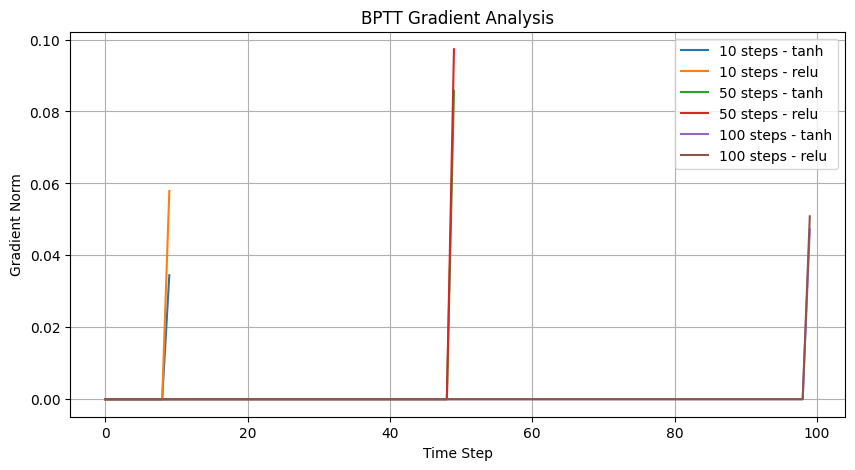

Vanishing gradients: Gradient values become very small.
Exploding gradients: Gradient values become extremely large.


In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Generate sample stock price data
np.random.seed(42)
prices = 100 + np.cumsum(np.random.normal(0, 1, 1200))

def analyse_gradients(sequence_length, activation):
    X = []
    y = []

    for i in range(len(prices) - sequence_length):
        X.append(prices[i:i + sequence_length])
        y.append(prices[i + sequence_length])

    X = np.array(X, dtype='float32')
    y = np.array(y, dtype='float32')

    # Normalise
    X = (X - X.mean()) / (X.std() + 1e-8)
    y = (y - prices.mean()) / (prices.std() + 1e-8)
    y = tf.cast(y, tf.float32)

    X = X.reshape(-1, sequence_length, 1)

    # Define layers individually to avoid sequential building issues
    rnn_layer = tf.keras.layers.SimpleRNN(
        32, activation=activation, return_sequences=True
    )
    dense_layer = tf.keras.layers.Dense(1)

    # Build layers by performing a dummy forward pass
    dummy_input = tf.zeros((32, sequence_length, 1))
    dummy_states = rnn_layer(dummy_input)
    dense_layer(dummy_states[:, -1, :])

    with tf.GradientTape() as tape:
        # Forward pass through RNN layer
        states = rnn_layer(X[:32])
        # Watch the intermediate states to calculate gradients with respect to them
        tape.watch(states)
        # Forward pass through final dense layer
        output = dense_layer(states[:, -1, :])
        # Reshape y to match the output dimension (32, 1)
        loss = tf.reduce_mean(tf.square(output - tf.reshape(y[:32], (-1, 1))))

    gradients = tape.gradient(loss, states)

    norms = tf.norm(gradients, axis=2).numpy().mean(axis=0)

    return norms

# Compare sequence lengths and activations
plt.figure(figsize=(10, 5))

for length in [10, 50, 100]:
    for activation in ['tanh', 'relu']:
        norms = analyse_gradients(length, activation)

        plt.plot(norms, label=f'{length} steps - {activation}')

plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.title("BPTT Gradient Analysis")
plt.legend()
plt.grid()
plt.show()

print("Vanishing gradients: Gradient values become very small.")
print("Exploding gradients: Gradient values become extremely large.")